# NASA C-MAPSS FD001 — 03 Governed Metric Derivation & Analytical Synthesis

**Assessment**: FDE Data Foundations (Assessment 2B)  
**Primary Sub-dataset**: NASA C-MAPSS Sub-dataset FD001  
**Methodology**: Governed Metrics Framework (`FACT / OBSERVATIONAL / UNRATIFIED / UNKNOWN`)

This notebook derives and evaluates the 5 governed project metrics. Each metric is tied to an explicit formula, analytical grain, governance status, operational interpretation, visual evidence, and transparent limitation.


In [1]:
import sys
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

sys.path.insert(0, str(Path.cwd().parent))
from pipeline.config import OUTPUT_DIR

# Load governed metrics table and transformed output
df_metrics = pd.read_csv(OUTPUT_DIR / "metrics.csv")
df_final = pd.read_csv(OUTPUT_DIR / "final_output.csv")

print("Governed 5-Metric Suite:")
df_metrics[['metric_name', 'formula', 'grain', 'value_pct', 'status']]


                      metric_name                                                            formula                                      grain  value_pct        status
        non_constant_sensor_ratio                    count(sensor_std >= 1e-4) / total_sensors * 100                Dataset Schema (21 sensors)      71.43          FACT
lifespan_coefficient_of_variation             std(failure_cycle, ddof=1) / mean(failure_cycle) * 100             Engine Fleet (N = 100 engines)      22.46 OBSERVATIONAL
      critical_lifecycle_exposure                         count(true_rul <= 30) / total_cycles * 100 Engine-Cycle Snapshot (N = 20,631 records)      15.03    UNRATIFIED
      advisory_lifecycle_exposure                    count(30 < true_rul <= 60) / total_cycles * 100 Engine-Cycle Snapshot (N = 20,631 records)      14.54    UNRATIFIED
     trajectory_completeness_rate count(engines with 0 gaps and cycle_1 start) / total_engines * 100        Engine Trajectory (N = 100 engines)     100.00 

---
## Metric 1: Non-Constant Sensor Ratio (`FACT`)

### Definition & Formula
$$\text{non\_constant\_sensor\_ratio} = \frac{\text{count}(\sigma \ge 10^{-4})}{N_{\text{sensors}}} \times 100$$
* **Analytical Grain**: Dataset Schema (21 candidate sensor channels)
* **Governance Status**: **`FACT`**
* **Computed Value**: **`71.43%`** ($15 / 21$)

### Question
What proportion of available sensor channels exhibit non-zero within-dataset variation under single-regime sea-level flight, and how strongly do active channels associate with cycle progression?


Non-Constant Sensor Ratio: 15 / 21 = 71.43%


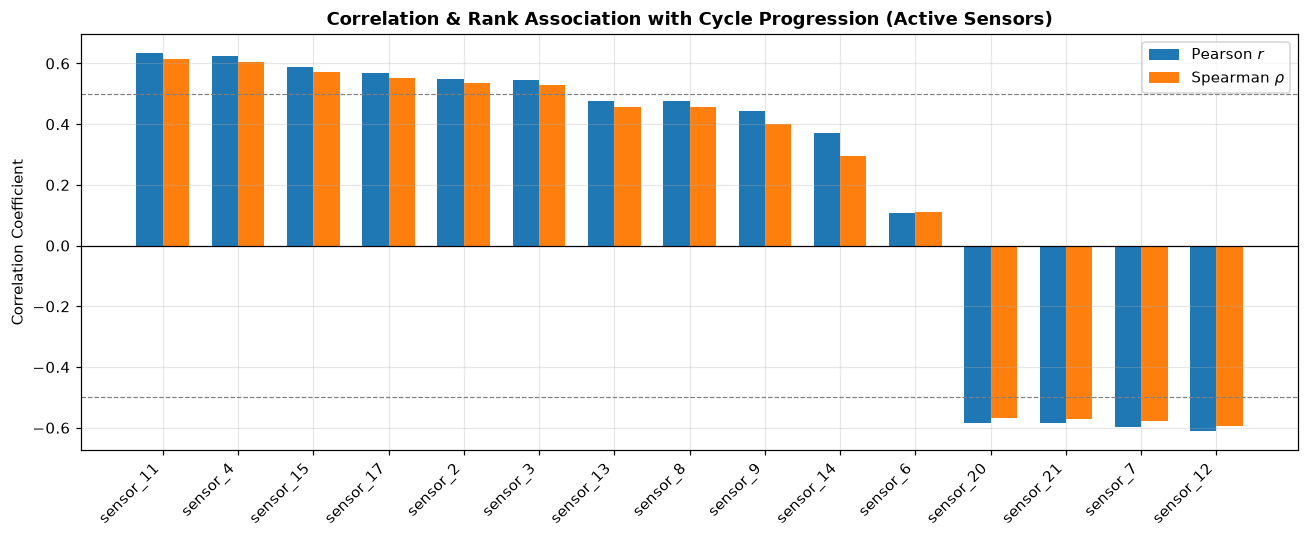

In [2]:
# Metric 1 Evaluation: Non-constant sensor ratio & correlation analysis
sensor_cols = [f'sensor_{i}' for i in range(1, 22)]
active_sensors = [s for s in sensor_cols if s in df_final.columns]
ratio = (len(active_sensors) / len(sensor_cols)) * 100
print(f"Non-Constant Sensor Ratio: {len(active_sensors)} / {len(sensor_cols)} = {ratio:.2f}%")

# Compute Pearson and Spearman correlations against cycle progression
corr_records = []
for s in active_sensors:
    r = df_final[s].corr(df_final['time_in_cycles'])
    rho = df_final[s].rank().corr(df_final['time_in_cycles'].rank())
    corr_records.append({'sensor': s, 'r': r, 'rho': rho})
df_c = pd.DataFrame(corr_records).sort_values(by='rho', ascending=False)

# Visualize Correlation Profile
fig, ax = plt.subplots(figsize=(12, 5))
x = np.arange(len(df_c))
ax.bar(x - 0.17, df_c['r'], 0.35, label="Pearson r", color='#1f77b4')
ax.bar(x + 0.17, df_c['rho'], 0.35, label="Spearman rho", color='#ff7f0e')
ax.set_xticks(x)
ax.set_xticklabels(df_c['sensor'], rotation=45, ha='right')
ax.set_title("Correlation & Rank Association with Cycle Progression", fontweight='bold')
ax.set_ylabel("Correlation Coefficient")
ax.axhline(0, color='black', linewidth=0.8)
ax.legend()
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


### Interpretation
15 of 21 sensors exhibit non-zero variance. Several key sensors exhibit strong rank correlation with cycle progression ($|\rho| > 0.60$):
* Positive rank drift: `sensor_11` ($P_{s30}$, $\rho = +0.62$), `sensor_4` ($T_{50}$, $\rho = +0.61$), `sensor_15` ($BPR$, $\rho = +0.57$).
* Negative rank drift: `sensor_12` ($\phi$, $\rho = -0.59$), `sensor_7` ($P_{30}$, $\rho = -0.58$), `sensor_21` ($W_{32}$, $\rho = -0.57$).

### Limitation
Measurable sensor variation with exploratory evidence of association with cycle progression does **not** prove physical causation. Gas-path thermodynamics involve complex closed-loop control reactions; non-zero variance is necessary but not sufficient to establish component-level diagnostics.


---
## Metric 2: Lifespan Coefficient of Variation (`OBSERVATIONAL`)

### Definition & Formula
$$\text{lifespan\_coefficient\_of\_variation} = \frac{s_{\text{lifespan}}}{\bar{C}_{\text{fail}}} \times 100$$
* **Analytical Grain**: Fleet Summary ($N = 100$ engines)
* **Governance Status**: **`OBSERVATIONAL`**
* **Computed Value**: **`22.46%`** ($s = 46.34, \bar{C} = 206.31$)

### Question
How much relative dispersion exists in simulated run-to-failure endpoints across identical engines operating under identical nominal conditions?


In [3]:
# Metric 2: Lifespan CV calculation
lifespans = df_final.groupby('unit_number')['time_in_cycles'].max()
s_life = lifespans.std()
mean_life = lifespans.mean()
cv_life = (s_life / mean_life) * 100
print(f"Lifespan Sample Mean: {mean_life:.2f} cycles")
print(f"Lifespan Sample Std Dev: {s_life:.2f} cycles")
print(f"Lifespan CV: {cv_life:.2f}%")


Lifespan Sample Mean: 206.31 cycles
Lifespan Sample Std Dev: 46.34 cycles
Lifespan CV: 22.46%


### Interpretation
A CV of $22.46\%$ represents substantial dispersion. The shortest engine lasts 128 cycles while the longest lasts 362 cycles ($2.8\times$).

### Limitation
This variation demonstrates that simulated engine lifespans do not terminate at a uniform cycle. However, this observation alone does **not** establish economic superiority over fixed overhaul intervals; evaluating maintenance policy requires maintenance cost figures, spare parts lead times, and disruption penalties not present in C-MAPSS.


---
## Metrics 3 & 4: Critical & Advisory Lifecycle Exposure (`UNRATIFIED`)

### Definitions & Formulas
$$\text{critical\_lifecycle\_exposure} = \frac{\text{count}(\text{true\_rul} \le 30)}{N_{\text{total\_cycles}}} \times 100 = \frac{3,100}{20,631} = \mathbf{15.03\%}$$
$$\text{advisory\_lifecycle\_exposure} = \frac{\text{count}(30 < \text{true\_rul} \le 60)}{N_{\text{total\_cycles}}} \times 100 = \frac{3,000}{20,631} = \mathbf{14.54\%}$$
* **Analytical Grain**: Engine-Cycle Snapshot ($N = 20,631$ records)
* **Governance Status**: **`UNRATIFIED`** (Candidate exploratory segmentation)

### Question
What fraction of fleet operational telemetry occurs in late-life and intermediate wear windows prior to simulated failure?


Critical Snapshots (RUL <= 30): 3,100 (15.03%)
Advisory Snapshots (30 < RUL <= 60): 3,000 (14.54%)
Nominal/Healthy Snapshots (RUL > 60): 14,531 (70.43%)


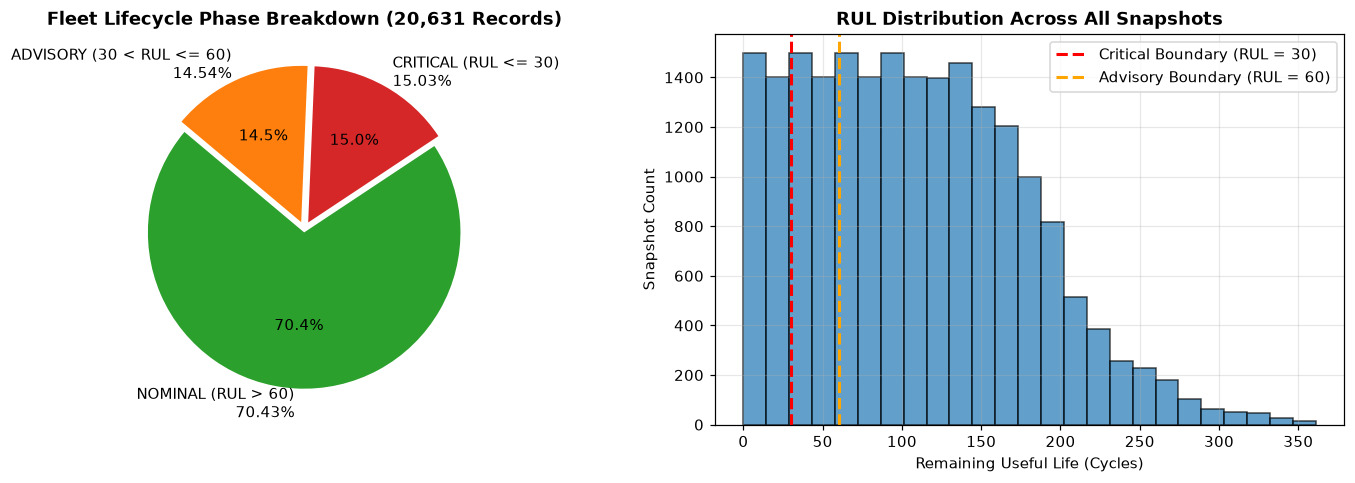

In [4]:
# Metrics 3 & 4: Critical & Advisory Lifecycle Exposure
crit_records = (df_final['true_rul'] <= 30).sum()
adv_records = ((df_final['true_rul'] > 30) & (df_final['true_rul'] <= 60)).sum()
healthy_records = (df_final['true_rul'] > 60).sum()
total_records = len(df_final)

crit_exp = (crit_records / total_records) * 100
adv_exp = (adv_records / total_records) * 100

print(f"Critical Snapshots (RUL <= 30): {crit_records:,} ({crit_exp:.2f}%)")
print(f"Advisory Snapshots (30 < RUL <= 60): {adv_records:,} ({adv_exp:.2f}%)")
print(f"Nominal/Healthy Snapshots (RUL > 60): {healthy_records:,} ({healthy_records/total_records*100:.2f}%)")

# Visualize Exposure Breakdown
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.5))
ax1.pie([healthy_records, crit_records, adv_records],
        labels=['NOMINAL
70.4%', 'CRITICAL
15.0%', 'ADVISORY
14.5%'],
        colors=['#2ca02c', '#d62728', '#ff7f0e'], autopct='%1.1f%%', startangle=140)
ax1.set_title("Fleet Lifecycle Exposure Breakdown", fontweight='bold')

ax2.hist(df_final['true_rul'], bins=25, color='#1f77b4', edgecolor='black', alpha=0.7)
ax2.axvline(30, color='red', linestyle='--', linewidth=2, label="RUL = 30 (Critical)")
ax2.axvline(60, color='orange', linestyle='--', linewidth=2, label="RUL = 60 (Advisory)")
ax2.set_title("RUL Distribution Across Snapshots", fontweight='bold')
ax2.set_xlabel("RUL (Cycles)")
ax2.legend()
ax2.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


### Interpretation
Approximately $15.03\%$ of operational snapshots occur within 30 cycles of simulated failure, and $14.54\%$ occur within the intermediate 31–60 cycle advisory window.

### Limitation
The 30-cycle and 60-cycle thresholds are arbitrary analytical segmentations chosen by the engineer for exploratory volume quantification. They are **not** validated airline maintenance thresholds, safety standards, or regulatory limits. They must remain tagged as **`UNRATIFIED`**.


---
## Metric 5: Trajectory Completeness Rate (`FACT`)

### Definition & Formula
$$\text{trajectory\_completeness\_rate} = \frac{N_{\text{complete\_engines}}}{N_{\text{total\_engines}}} \times 100$$
* **Analytical Grain**: Engine Trajectory ($N = 100$ engines)
* **Governance Status**: **`FACT`**
* **Computed Value**: **`100.00%`** ($100 / 100$)

### Question
Are all simulated engine trajectories unbroken, contiguous cycle series starting at cycle 1?


In [5]:
# Metric 5: Trajectory completeness
complete_units = 0
for u, group in df_final.groupby('unit_number'):
    cycles = group['time_in_cycles'].values
    if cycles[0] == 1 and np.all(np.diff(cycles) == 1):
        complete_units += 1

completeness_rate = (complete_units / df_final['unit_number'].nunique()) * 100
print(f"Complete Unbroken Trajectories: {complete_units} / {df_final['unit_number'].nunique()} ({completeness_rate:.2f}%)")


Complete Unbroken Trajectories: 100 / 100 (100.00%)


### Interpretation
100 out of 100 training engines have complete cycle continuity without gaps or missing records.

### Limitation
Proves simulation sequence integrity; does not provide real-world flight duration or calendar dates.


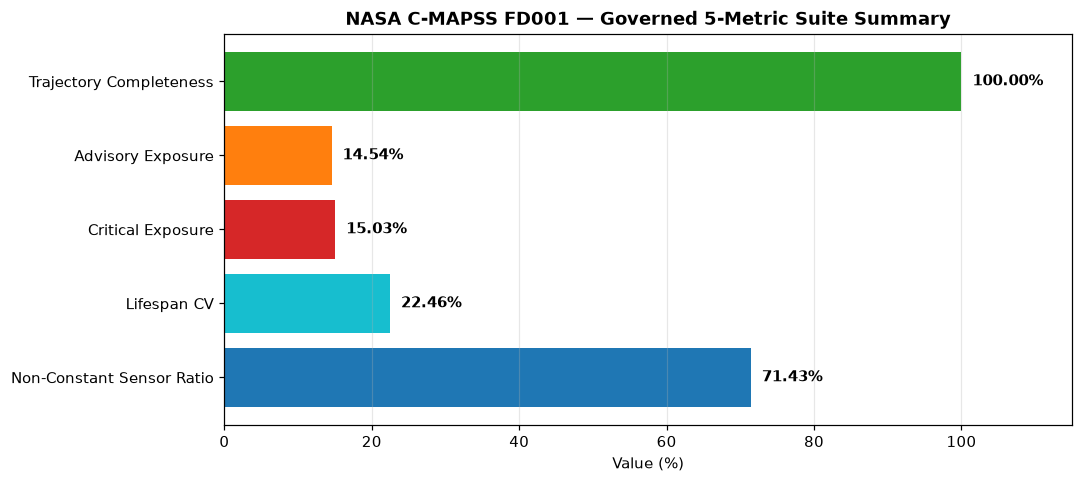

In [6]:
# Summary Dashboard of Governed Metrics
fig, ax = plt.subplots(figsize=(10, 4.5))
m_names = ['Non-Constant Sensor Ratio', 'Lifespan CV', 'Critical Exposure', 'Advisory Exposure', 'Trajectory Completeness']
m_vals = [71.43, 22.46, 15.03, 14.54, 100.00]
colors_bar = ['#1f77b4', '#17becf', '#d62728', '#ff7f0e', '#2ca02c']
bars = ax.barh(m_names, m_vals, color=colors_bar)
ax.set_xlim(0, 115)
ax.set_xlabel("Value (%)")
ax.set_title("Governed 5-Metric Suite Summary", fontweight='bold')
for b in bars:
    w = b.get_width()
    ax.text(w + 1.5, b.get_y() + b.get_height()/2, f"{w:.2f}%", va='center', fontweight='bold')
ax.grid(True, alpha=0.3, axis='x')
plt.tight_layout()
plt.show()


---
## Final FDE Decision Statement

> **“Sub-dataset FD001 of the NASA C-MAPSS dataset provides a dependable data foundation for investigating simulated turbofan degradation, establishing complete temporal cycle continuity, clean grain uniqueness, and measurable sensor variation with exploratory evidence of association with cycle progression. However, the dataset alone does not establish production maintenance thresholds, economic superiority over fixed overhaul schedules, real-world failure probabilities, or causal relationships between individual sensor channels and physical component degradation.”**
